# Churn model: from SQL training table to explained predictions

Everything here uses the platform's own code (`core/`), so the notebook shows what the pipeline does; it is not a separate implementation.

**Business question:** which active customers are most likely to cancel in the next 60 days, and what drives it?

Run order: the SQL layer (`scripts.run_sql all`) must have built `training_set` first.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from core.use_case import load_use_case
from core.sql_runner import read_training_set
from core.ml_pipeline import train_from_frame
from core.drift import drift_report
from core.sql_runner import features_as_of
from core.ml_pipeline import prepare_frame

SCHEMA = os.environ.get("NB_SCHEMA", "ws_demo")
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.alpha": .25, "figure.dpi": 110, "font.size": 10})
uc = load_use_case("churn")
df = read_training_set(SCHEMA)
print(f"{len(df):,} customers, {int(df['churned'].sum())} churned in the 60-day window ({df['churned'].mean():.1%})")
df.head()

2,403 customers, 202 churned in the 60-day window (8.4%)


,customer_id,tenure_days,monthly_price_ghs,contract_months,avg_data_used_gb_3m,usage_change_pct,avg_active_days_3m,failed_payments_90d,tickets_90d,network_tickets_90d,avg_resolution_hours_90d,avg_satisfaction,plan_name,region,acquisition_channel,customer_type,churned
0,1,387,120.0,6,34.62,6.2,13.7,0,0,0,NaN,NaN,Standard 40GB,Eastern,agent,individual,0
1,3,290,120.0,6,11.75,14.4,12.3,0,1,0,30.8,4.0,Standard 40GB,Ashanti,agent,individual,0
2,7,102,35.0,0,1.04,NaN,9.7,0,0,0,NaN,NaN,Starter 5GB,Greater Accra,walk-in,individual,1
3,14,357,35.0,0,2.64,3.5,22.7,0,1,0,94.6,3.0,Starter 5GB,Ashanti,referral,individual,0
4,15,725,120.0,6,15.11,28.2,23.7,1,0,0,NaN,NaN,Standard 40GB,Central,agent,business,0


## 1. The data the model sees
One row per active customer at the cutoff (2026-06-30). Features use only data up to that date; the label looks 60 days after it. Missing values are real (usage and satisfaction have gaps); the pipeline handles them instead of dropping rows.

In [2]:
miss = df[uc.feature_columns].isna().mean().sort_values(ascending=False)
miss[miss > 0].map("{:.1%}".format).to_frame("missing")

,missing
avg_satisfaction,86.9%
avg_resolution_hours_90d,76.3%
usage_change_pct,25.1%
avg_data_used_gb_3m,0.5%
avg_active_days_3m,0.3%


## 2. Baseline vs better models
The baseline (`DummyClassifier`) predicts the base rate for everybody, so it has no skill by construction (AUC 0.5). A model is only worth keeping if it clearly beats it.
Models are chosen by **cross-validation inside the train split**. The test set is only used to report.

In [3]:
r = train_from_frame(df, uc)
comp = r["comparison"]
cols = ["model", "role", "selected", "cv_score", "test_roc_auc", "test_average_precision", "test_precision", "test_recall", "test_f1", "test_lift"]
comp[cols].round(3)

,model,role,selected,cv_score,test_roc_auc,test_average_precision,test_precision,test_recall,test_f1,test_lift
0,dummy_classifier,baseline,False,0.500,0.500,0.083,0.102,0.125,0.112,1.227
1,logistic_regression,candidate,False,0.744,0.807,0.374,0.306,0.375,0.337,3.681
2,gradient_boosting,candidate,True,0.757,0.808,0.393,0.306,0.375,0.337,3.681


In [4]:
print(f"Selected: {r['best_name']}")
print(f"Test set: {len(r['y_test'])} customers, {int(r['y_test'].sum())} churners -> small, so single numbers are noisy.")
m = r["card"]["test_metrics"]
print(f"Flagging the riskiest {uc.evaluation.flag_top_fraction:.0%} ({m['flagged']} customers): "
      f"precision {m['precision']:.1%}, recall {m['recall']:.1%}, lift {m['lift']:.1f}x vs picking at random")

Selected: gradient_boosting
Test set: 481 customers, 40 churners -> small, so single numbers are noisy.
Flagging the riskiest 10% (49 customers): precision 30.6%, recall 37.5%, lift 3.7x vs picking at random


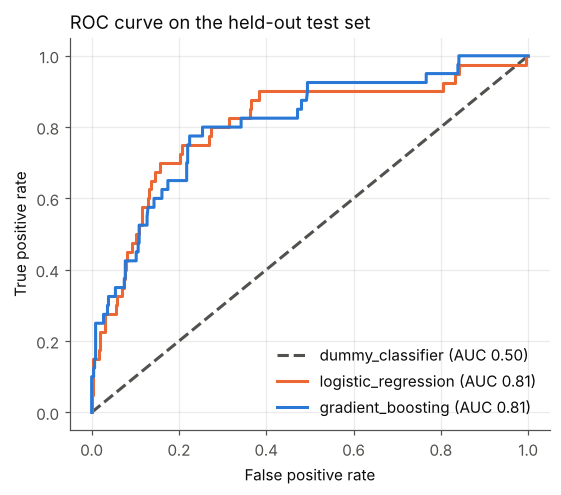

In [5]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
styles = {uc.models.baseline: (MUTED, "--"), "logistic_regression": (ORANGE, "-"), "gradient_boosting": (BLUE, "-")}
for name, sc in r["all_test_scores"].items():
    fpr, tpr, _ = roc_curve(r["y_test"], sc)
    auc = comp.set_index("model").loc[name, "test_roc_auc"]
    col, ls = styles.get(name, (AQUA, "-"))
    ax.plot(fpr, tpr, color=col, ls=ls, lw=2, label=f"{name} (AUC {auc:.2f})")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curve on the held-out test set", loc="left"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 3. Does it help the retention team? (decile view)
Customers are scored with **out-of-fold** predictions (each scored by a model that never saw them). Decile 10 = riskiest 10%. If the model works, churn concentrates in the top deciles.

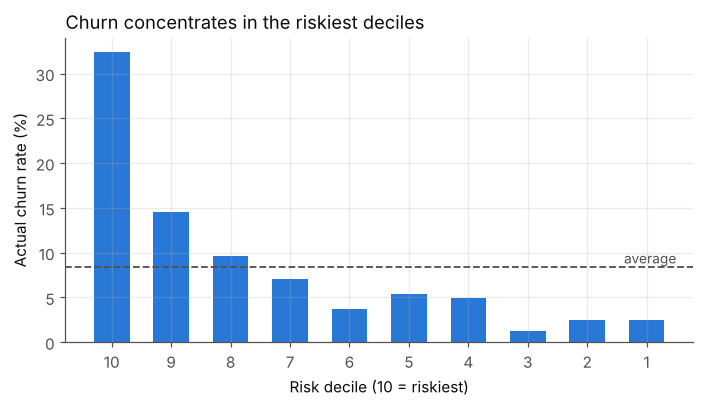

,customers,churned,churn_rate,share_of_all_churners
risk_decile,,,,
10,241,78,0.324,0.386
9,240,35,0.146,0.173
8,240,23,0.096,0.114
7,241,17,0.071,0.084
6,240,9,0.038,0.045
5,240,13,0.054,0.064
4,241,12,0.050,0.059
3,240,3,0.012,0.015
2,240,6,0.025,0.030


In [6]:
s = r["scored"]
dec = s.groupby("risk_decile").agg(customers=("actual", "size"), churned=("actual", "sum"), churn_rate=("actual", "mean")).sort_index(ascending=False)
dec["share_of_all_churners"] = dec["churned"] / dec["churned"].sum()
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(dec.index.astype(str), dec["churn_rate"] * 100, color=BLUE, width=.6)
ax.axhline(s["actual"].mean() * 100, color=MUTED, ls="--", lw=1.2)
ax.text(len(dec) - .5, s["actual"].mean() * 100 + .4, "average", ha="right", color=MUTED, fontsize=9)
ax.set_xlabel("Risk decile (10 = riskiest)"); ax.set_ylabel("Actual churn rate (%)")
ax.set_title("Churn concentrates in the riskiest deciles", loc="left"); plt.tight_layout(); plt.show()
dec.round(3)

## 4. What drives the prediction
Permutation importance on the test set: shuffle one feature and see how much the score drops. `clearly_matters` means the drop is bigger than 2 standard deviations of the shuffling noise. Direction says which way the feature pushes the score (this is association in the data, not proof of cause).

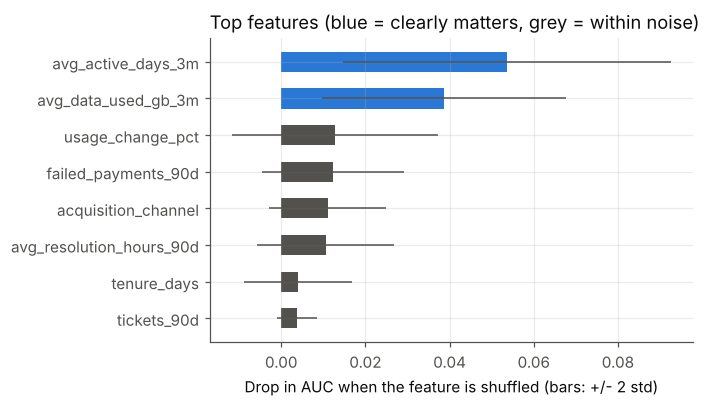

,feature,importance,std,clearly_matters,direction
0,avg_active_days_3m,0.0536,0.0195,True,higher value -> lower score
1,avg_data_used_gb_3m,0.0386,0.0145,True,higher value -> lower score
2,usage_change_pct,0.0127,0.0122,False,higher value -> lower score
3,failed_payments_90d,0.0123,0.0084,False,higher value -> higher score
4,acquisition_channel,0.0110,0.0069,False,highest score: online; lowest: referral
5,avg_resolution_hours_90d,0.0106,0.0081,False,higher value -> higher score
6,tenure_days,0.0040,0.0064,False,higher value -> lower score
7,tickets_90d,0.0037,0.0024,False,higher value -> higher score
8,network_tickets_90d,0.0017,0.0032,False,higher value -> higher score
9,region,0.0012,0.0012,False,highest score: Central; lowest: Western


In [7]:
imp = r["importance"]
top = imp.head(8)[::-1]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.barh(top["feature"], top["importance"], xerr=2 * top["std"], color=[BLUE if c else MUTED for c in top["clearly_matters"]], height=.55,
        error_kw=dict(ecolor=MUTED, lw=1))
ax.set_xlabel("Drop in AUC when the feature is shuffled (bars: +/- 2 std)")
ax.set_title("Top features (blue = clearly matters, grey = within noise)", loc="left"); plt.tight_layout(); plt.show()
imp[["feature", "importance", "std", "clearly_matters", "direction"]].round(4)

## 5. Drift check
Same SQL, later cutoff (2026-08-31), compared to the training data with PSI. The synthetic data is stationary, so everything should be stable. The tests in `tests/test_ml_pipeline.py` prove the PSI does flag a real shift.

In [8]:
import joblib
bundle = joblib.load(ROOT / "outputs" / "ml" / "churn" / "model.joblib")
new = prepare_frame(features_as_of(SCHEMA, uc, "2026-08-31"), uc)
X = new[bundle["features"]]
rep = drift_report(bundle, X, bundle["pipeline"].predict_proba(X)[:, 1])
rep.round(4)

,variable,kind,psi,status
0,usage_change_pct,numeric,0.0154,stable
1,MODEL SCORE,score,0.0123,stable
2,tenure_days,numeric,0.0099,stable
3,avg_resolution_hours_90d,numeric,0.0094,stable
4,avg_active_days_3m,numeric,0.0052,stable
5,avg_satisfaction,numeric,0.0035,stable
6,avg_data_used_gb_3m,numeric,0.0033,stable
7,region,categorical,0.0013,stable
8,failed_payments_90d,numeric,0.0013,stable
9,acquisition_channel,categorical,0.0009,stable


## 6. Limits to keep in mind
- Random split, not time-based: a production check should train on earlier cutoffs and test on a later one.
- ~40 churners in the test set: AUC/precision have wide error bars. Cross-validation on train is the steadier signal.
- Synthetic data: effects here are planted by the generator; do not read them as real-world findings.
- Final model is trained on the train split only (80%).